In [74]:
#!pip install gurobipy 
#!pip install gurobi-machinelearning 
#!pip install scipy 
#!pip install torch 
#!pip install scikit-learn 
#!pip install keras 
#!pip install xgboost 
#!pip install lightgbm 
#!pip install python-mnist 
#!pip install np_utils
#!pip install tensorflow
#!pip install matplotlib
#!pip install seaborn
#!pip install numpy
#!pip install pandas


# Adversarial Machine Learning

In this example, we show how to use Gurobi Machine Learning to construct
an adversarial example for a trained neural network.

We use the MNIST handwritten digit database
(http://yann.lecun.com/exdb/mnist/) for this example.

For this problem, we are given a trained neural network and one well
classified example $\bar x$. Our goal is to construct another
example $x$ *close to* $\bar x$ that is classified with a
different label.

For the hand digit recognition problem, the input is a grayscale image
of $28 \times 28$ ($=784$) pixels and the output is a vector
of length 10 (each entry corresponding to a digit). We denote the output
vector by $y$. The image is classified according to the largest
entry of $y$.

For the training example, assume that coordinate $l$ of the output
vector is the one with the largest value giving the correct label. We
pick a coordinate corresponding to another label, denoted $w$, and
we want the difference between $y_w - y_l$ to be as large as
possible.

If we can find a solution where this difference is positive, then
$x$ is a *counter-example* receiving a different label. If instead
we can show that the difference is never positive, no such example
exists.

Here, we use the $l_1-$ norm $|| x - \bar x||_1$ to define
the neighborhood with its size defined by a fixed parameter
$\delta$:

\begin{align}|| x - \bar x ||_1 \le \delta.\end{align}

Denoting by $g$ the prediction function of the neural network, the
full optimization model reads:

\begin{align}\begin{aligned}
   &\max y_w - y_l \\
   &\text{subject to:}\\
   &|| x - \bar x ||_1 \le \delta,\\\
   & y = g(x).
   \end{aligned}\end{align}

Note that our model is inspired by Fischet al. (2018).

## Imports and loading data

First, we import the required packages for this example.

In addition to the usual packages, we will need ``matplotlib`` to plot
the digits, and ``joblib`` to load a pre-trained network and part of the
training data.

Note that from the ``gurobi_ml`` package we need to use directly the
``add_mlp_regressor_constr`` function for reasons that will be clarified
later.


In [102]:
import random
import gurobipy as gp
import numpy as np
import pandas as pd
#from matplotlib import pyplot as plt

from gurobi_ml.sklearn import add_mlp_regressor_constr

from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation
from keras.utils import to_categorical

from sklearn.neural_network import MLPClassifier

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [104]:
from pathlib import Path
result_path = Path('result/')

We load a neural network that was pre-trained with Scikit-learn’s
MLPRegressor. The network is small (2 hidden layers of 50 neurons),
finding a counter example shouldn’t be too difficult.

We also load the first 100 training examples of the MNIST dataset that
we saved to avoid having to reload the full data set.




In [105]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("X_train shape", X_train.shape)
print("y_train shape", y_train.shape)
print("X_test shape", X_test.shape)
print("y_test shape", y_test.shape)

X_train shape (60000, 28, 28)
y_train shape (60000,)
X_test shape (10000, 28, 28)
y_test shape (10000,)


In [106]:
X_train = X_train.reshape(60000, 784)
X_test = X_test.reshape(10000, 784)

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train /= 255
X_test /= 255

print("Training matrix shape", X_train.shape)
print("Testing matrix shape", X_test.shape)

Training matrix shape (60000, 784)
Testing matrix shape (10000, 784)


In [107]:
no_classes = 10

Y_train = to_categorical(y_train, no_classes)
Y_test = to_categorical(y_test, no_classes)

In [108]:
model = MLPClassifier(
    hidden_layer_sizes = (512, 512),
    activation = 'relu',
    solver = 'adam',
    alpha = 0.001,
    max_iter = 20,
    verbose = True
)

In [109]:
model.fit(X_train, Y_train)

Iteration 1, loss = 0.60166063
Iteration 2, loss = 0.19536290
Iteration 3, loss = 0.12572719
Iteration 4, loss = 0.08901974
Iteration 5, loss = 0.06342929
Iteration 6, loss = 0.04692131
Iteration 7, loss = 0.03575603
Iteration 8, loss = 0.02883648
Iteration 9, loss = 0.02732974
Iteration 10, loss = 0.02065981
Iteration 11, loss = 0.01694533
Iteration 12, loss = 0.01947003
Iteration 13, loss = 0.02690748
Iteration 14, loss = 0.02038277
Iteration 15, loss = 0.01330170
Iteration 16, loss = 0.01110407
Iteration 17, loss = 0.02148911
Iteration 18, loss = 0.02012431
Iteration 19, loss = 0.01335375
Iteration 20, loss = 0.01283697


/home/jossian/.local/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


,hidden_layer_sizes,"(512, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,20
,shuffle,True
,random_state,None


In [110]:
# 4. Fazer previsões no conjunto de teste
y_pred = model.predict(X_test)

In [111]:
# 5. Extrair e imprimir as estatísticas

# Acurácia
acuracia = accuracy_score(Y_test, y_pred)
print(f"Acurácia do modelo: {acuracia:.4f}\n")

y_test_labels = np.argmax(Y_test, axis=1)
y_pred_labels = np.argmax(y_pred, axis=1)

Acurácia do modelo: 0.9751



Matriz de Confusão:



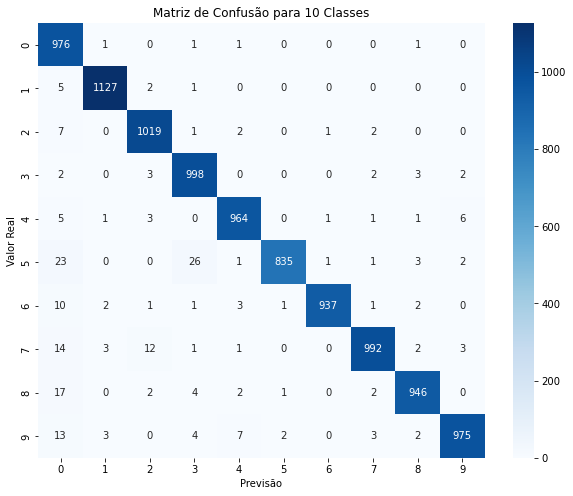

In [112]:
# Matriz de Confusão
print("Matriz de Confusão:\n")
cm = confusion_matrix(y_test_labels, y_pred_labels)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Previsão')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusão para 10 Classes')
plt.show()

In [113]:
# Relatório de Classificação
print("\nRelatório de Classificação:\n")
print(classification_report(Y_test, y_pred))


Relatório de Classificação:

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.99      0.98      1032
           3       0.96      0.99      0.98      1010
           4       0.98      0.98      0.98       982
           5       1.00      0.94      0.97       892
           6       0.99      0.98      0.99       958
           7       0.98      0.97      0.98      1028
           8       0.98      0.98      0.98       974
           9       0.98      0.97      0.98      1009

   micro avg       0.98      0.98      0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000
 samples avg       0.98      0.98      0.98     10000



/home/jossian/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## Choose an example and set labels

Now we choose an example. Here we chose arbitrarily example 26. We plot
the example and verify if it is well predicted by calling the
``predict`` function.




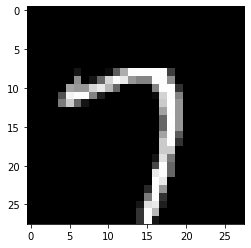

In [114]:
# Choose an example
exampleno = 26
example = X_test[exampleno : exampleno + 1, :]

plt.imshow(example.reshape((28, 28)), cmap="gray")

In [115]:
print(f"Predicted label {model.predict(example)}")

Predicted label [[0 0 0 0 0 0 0 1 0 0]]


To set up the objective function of the optimization model, we also need
to find a wrong label.

We use ``predict_proba`` to get the weight given by the neural network
to each label. We then use ``numpy``\ ’s ``argsort`` function to get the
labels sorted by their weight. The right label is then the last element
in the list, and we pick the next to last element as the wrong label.




In [116]:
ex_prob = model.predict_proba(example)
sorted_labels = np.argsort(ex_prob)[0]
right_label = sorted_labels[-1]
wrong_label = sorted_labels[-2]

## Building the optimization model

Now all the data is gathered, and we proceed to building the
optimization model.

We create a matrix variable ``x`` corresponding to the new input of the
neural network we want to compute and a ``y`` matrix variable for the
output of the neural network. Those variables should have respectively
the shape of the example we picked and the shape of the return value of
``predict_proba``.

We need additional variables to model the $l1-$\ norm constraint.
Namely, for each pixel in the image, we need to measure the absolute
difference between $x$ and $\bar x$. The corresponding
matrix variable has the same shape as ``x``.

We set the objective which is to maximize the difference between the
*wrong* label and the *right* label.




In [117]:
m = gp.Model()
delta = 5

x = m.addMVar(example.shape, lb=0.0, ub=1.0, name="x")
y = m.addMVar(ex_prob.shape, lb=-gp.GRB.INFINITY, name="y")

abs_diff = m.addMVar(example.shape, lb=0, ub=1, name="abs_diff")

m.setObjective(y[0, wrong_label] - y[0, right_label], gp.GRB.MAXIMIZE)

The $l1-$\ norm constraint is formulated with:

\begin{align}\eta \ge x - \bar x \\
   \eta \ge \bar x - x \\
   \sum \eta \le \delta\end{align}

With $\eta$ denoting the ``absdiff`` variables.

Those constraints are naturally expressed with Gurobi’s Matrix API.




In [118]:
# Bound on the distance to example in norm-1
m.addConstr(abs_diff >= x - example)
m.addConstr(abs_diff >= -x + example)
m.addConstr(abs_diff.sum() <= delta)

# Update the model
m.update()

Finally, we insert the neural network in the ``gurobipy`` model to link
``x`` and ``y``.

Note that this case is not as straightforward as others. The reason is
that the neural network is trained for classification with a
``"softmax"`` activation in the last layer. But in this model we are
using the network without activation in the last layer.

For this reason, we change manually the last layer activation before
adding the network to the Gurobi model.

Also, we use the function
:func:`add_mlp_regressor_constr <gurobi_ml.sklearn.mlpregressor.add_mlp_regressor_constr>`.
directly. The network being actually for classification (i.e. of type
``MLPClassifier``) the
:func:`add_predictor_constr <gurobi_ml.add_predictor_constr>`.
function would not handle it automatically.

In the output, there is a warning about adding constraints with very
small coefficients that are ignored. Neural-networks often contain very
small coefficients in their expressions. Any coefficient with an
absolute value smaller than $10^{-13}$ is ignored by Gurobi. This
may result in slightly different predicted values but should be
negligible.




In [119]:
# Change last layer activation to identity
model.out_activation_ = "identity"
# Code to add the neural network to the constraints
pred_constr = add_mlp_regressor_constr(m, model, x, y)

# Restore activation
model.out_activation_ = "softmax"

Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


The model should be complete. We print the statistics of what was added
to insert the neural network into the optimization model.




In [120]:
pred_constr.print_stats()

Model for mlpclassifier:
2048 variables
1034 constraints
1024 general constraints
Input has shape (1, 784)
Output has shape (1, 10)

--------------------------------------------------------------------------------
Layer           Output Shape    Variables              Constraints              
                                                Linear    Quadratic      General
dense               (1, 512)         1024          512            0          512 (relu)

dense0              (1, 512)         1024          512            0          512 (relu)

dense1               (1, 10)            0           10            0            0

--------------------------------------------------------------------------------


## Solving the model

We now turn to solving the optimization model. Solving the adversarial
problem, as we formulated it above, doesn’t actually require computing a
provably optimal solution. Instead, we need to either:

-  find a feasible solution with a positive objective cost (i.e. a
   counter-example), or
-  prove that there is no solution of positive cost (i.e. no
   counter-example in the neighborhood exists).

We can use Gurobi parameters to limit the optimization to answer those
questions: setting
[BestObjStop](https://www.gurobi.com/documentation/current/refman/bestobjstop.html#parameter:BestObjStop)_
to 0.0 will stop the optimizer if a counter-example is found, setting
[BestBdStop](https://www.gurobi.com/documentation/current/refman/bestobjstop.html#parameter:BestBdStop)_
to 0.0 will stop the optimization if the optimizer has shown there is no
counter-example.

We set the two parameters and optimize.




In [121]:
# configurando parametros

m.Params.BestBdStop = 0.0
m.Params.BestObjStop = 0.0

#m.Params.IterationLimit = 1000 # define o número de iterações do simplex
m.Params.TimeLimit = 120 # define tempo limite
m.Params.MIPGap = 0.001 # define valor do gap
m.Params.method = 1
m.Params.NodeMethod = 1 # -1=automatic,0=primal simplex,1=dual simplex,2=barrier
#m.Params.Threads = 1
#m.Params.Presolve = 0
#m.Params.Cuts = 0

m.setParam("LogFile", "my_model_log.log")

m.Params.LogToConsole = 0 # To send the log to a file only
m.Params.OutputFlag = 1

Set parameter BestBdStop to value 0
Set parameter BestObjStop to value 0
Set parameter TimeLimit to value 120
Set parameter MIPGap to value 0.001
Set parameter Method to value 1
Set parameter NodeMethod to value 1
Set parameter LogFile to value "my_model_log.log"
Set parameter LogToConsole to value 0


In [122]:
m.write("model_params.prm")

In [123]:
m.optimize()

In [124]:
print(f"End status = {m.status}")

End status = 9


In [125]:
# if model.status == gp.GRB.OPTIMAL:
m.write("my_solution.sol") 

## Results

Normally, for the example and $\delta$ we chose, a counter example
that gets the wrong label is found. We finish this notebook by plotting
the counter example and printing how it is classified by the neural
network.




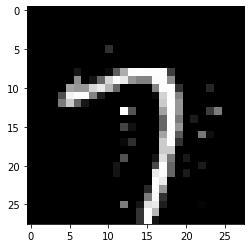

In [126]:
plt.imshow(x.X.reshape((28, 28)), cmap="gray")

In [127]:
print(f"Solution is classified as {model.predict(x.X)}")

Solution is classified as [[0 0 0 0 0 0 0 1 0 0]]


Copyright © 2023 Gurobi Optimization, LLC


